<a href="https://colab.research.google.com/github/asiyairshad/AI-research-assistance/blob/master/ecg_hybrid_cnn_vqc.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install pennylane wfdb scikit-learn scipy seaborn



     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 44.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 32.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.5/51.5 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 32.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 25.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 167.2/167.2 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 28.9 MB/s eta 0:00:00


In [ ]:
import ast
import os
import re
import urllib.request

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb

from tqdm.auto import tqdm
from scipy.signal import butter, filtfilt

from sklearn.model_selection import StratifiedGroupKFold


In [ ]:
SEED = 42

np.random.seed(SEED)

BASE_URL = "https://physionet.org/files/ptb-xl/1.0.3/"
DATA_DIR = Path("/content/ptbxl_records100")

DATA_DIR.mkdir(
    parents=True,
    exist_ok=True
)


In [ ]:
database_url = BASE_URL + "ptbxl_database.csv"
scp_url = BASE_URL + "scp_statements.csv"

database = pd.read_csv(database_url)
scp_statements = pd.read_csv(
    scp_url,
    index_col=0
)

print("Database shape:", database.shape)
print(database.columns.tolist())
database.head()


Database shape: (21799, 28)
['ecg_id', 'patient_id', 'age', 'sex', 'height', 'weight', 'nurse', 'site', 'device', 'recording_date', 'report', 'scp_codes', 'heart_axis', 'infarction_stadium1', 'infarction_stadium2', 'validated_by', 'second_opinion', 'initial_autogenerated_report', 'validated_by_human', 'baseline_drift', 'static_noise', 'burst_noise', 'electrodes_problems', 'extra_beats', 'pacemaker', 'strat_fold', 'filename_lr', 'filename_hr']


,ecg_id,patient_id,age,sex,height,weight,nurse,site,device,recording_date,...,validated_by_human,baseline_drift,static_noise,burst_noise,electrodes_problems,extra_beats,pacemaker,strat_fold,filename_lr,filename_hr
0,1,15709.0,56.0,1,NaN,63.0,2.0,0.0,CS-12 E,1984-11-09 09:17:34,...,True,NaN,", I-V1,",NaN,NaN,NaN,NaN,3,records100/00000/00001_lr,records500/00000/00001_hr
1,2,13243.0,19.0,0,NaN,70.0,2.0,0.0,CS-12 E,1984-11-14 12:55:37,...,True,NaN,NaN,NaN,NaN,NaN,NaN,2,records100/00000/00002_lr,records500/00000/00002_hr
2,3,20372.0,37.0,1,NaN,69.0,2.0,0.0,CS-12 E,1984-11-15 12:49:10,...,True,NaN,NaN,NaN,NaN,NaN,NaN,5,records100/00000/00003_lr,records500/00000/00003_hr
3,4,17014.0,24.0,0,NaN,82.0,2.0,0.0,CS-12 E,1984-11-15 13:44:57,...,True,", II,III,AVF",NaN,NaN,NaN,NaN,NaN,3,records100/00000/00004_lr,records500/00000/00004_hr
4,5,17448.0,19.0,1,NaN,70.0,2.0,0.0,CS-12 E,1984-11-17 10:43:15,...,True,", III,AVR,AVF",NaN,NaN,NaN,NaN,NaN,4,records100/00000/00005_lr,records500/00000/00005_hr


In [ ]:
TARGET_LABELS = {
    "SR": "SR",
    "AFIB": "AFIB",
    "STACH": "STACH"
}

def parse_scp_codes(value):v
    if isinstance(value, dict):
        return value

    return ast.literal_eval(value)

def create_rhythm_label(value):
    codes = parse_scp_codes(value)

    matching_labels = [
        TARGET_LABELS[code]
        for code in TARGET_LABELS
        if code in codes
    ]

    if len(matching_labels) == 1:
        return matching_labels[0]

    return np.nan

database["label"] = database["scp_codes"].apply(
    create_rhythm_label
)

labeled_data = database.dropna(
    subset=["label"]
).copy()

print(labeled_data["label"].value_counts())


label
SR       16748
AFIB      1514
STACH      826
Name: count, dtype: int64


In [ ]:
train_pool = labeled_data[
    labeled_data["strat_fold"] <= 8
].copy()

validation_pool = labeled_data[
    labeled_data["strat_fold"] == 9
].copy()

test_pool = labeled_data[
    labeled_data["strat_fold"] == 10
].copy()

print("Training pool:")
print(train_pool["label"].value_counts())

print("\nValidation pool:")
print(validation_pool["label"].value_counts())

print("\nTest pool:")
print(test_pool["label"].value_counts())


Training pool:
label
SR       13404
AFIB      1211
STACH      661
Name: count, dtype: int64

Validation pool:
label
SR       1670
AFIB      151
STACH      83
Name: count, dtype: int64

Test pool:
label
SR       1674
AFIB      152
STACH      82
Name: count, dtype: int64


In [ ]:
N_TRAIN_PER_CLASS = 200
N_VALIDATION_PER_CLASS = 50
N_TEST_PER_CLASS = 50


In [ ]:
def balanced_sample(
    dataframe,
    n_per_class,
    random_state=42
):
    selected_groups = []

    for label in TARGET_LABELS.values():
        group = dataframe[
            dataframe["label"] == label
        ]

        number_to_select = min(
            n_per_class,
            len(group)
        )

        selected_groups.append(
            group.sample(
                n=number_to_select,
                random_state=random_state
            )
        )

    result = pd.concat(
        selected_groups,
        ignore_index=True
    )

    return result.sample(
        frac=1,
        random_state=random_state
    ).reset_index(drop=True)


In [ ]:
train_data = balanced_sample(
    train_pool,
    N_TRAIN_PER_CLASS,
    SEED
)

validation_data = balanced_sample(
    validation_pool,
    N_VALIDATION_PER_CLASS,
    SEED
)

test_data = balanced_sample(
    test_pool,
    N_TEST_PER_CLASS,
    SEED
)

train_data["split"] = "train"
validation_data["split"] = "validation"
test_data["split"] = "test"

manifest = pd.concat(
    [
        train_data,
        validation_data,
        test_data
    ],
    ignore_index=True
)

print("Train records:", len(train_data))
print("Validation records:", len(validation_data))
print("Test records:", len(test_data))


Train records: 600
Validation records: 150
Test records: 150


In [ ]:
train_patients = set(
    train_data["patient_id"]
)

validation_patients = set(
    validation_data["patient_id"]
)

test_patients = set(
    test_data["patient_id"]
)

print(
    "Train-validation overlap:",
    len(train_patients.intersection(validation_patients))
)

print(
    "Train-test overlap:",
    len(train_patients.intersection(test_patients))
)

print(
    "Validation-test overlap:",
    len(validation_patients.intersection(test_patients))
)


Train-validation overlap: 0
Train-test overlap: 0
Validation-test overlap: 0


In [ ]:
def remove_extension(filename):
    filename = str(filename).replace(
        "\\",
        "/"
    )

    filename = re.sub(
        r"\.(dat|hea)$",
        "",
        filename
    )

    return filename


In [ ]:
def download_record(filename):
    relative_stem = remove_extension(filename)

    local_stem = DATA_DIR / relative_stem
    local_stem.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    for extension in [".hea", ".dat"]:
        local_file = Path(
            str(local_stem) + extension
        )

        remote_url = (
            BASE_URL
            + relative_stem
            + extension
        )

        if not local_file.exists():
            urllib.request.urlretrieve(
                remote_url,
                local_file
            )

    return str(local_stem)


In [ ]:
local_paths = []

for _, row in tqdm(
    manifest.iterrows(),
    total=len(manifest),
    desc="Downloading ECG records"
):
    local_paths.append(
        download_record(row["filename_lr"])
    )

manifest["local_path"] = local_paths

print(
    "Downloaded records:",
    len(manifest)
)


Downloaded records: 900


In [ ]:
example_path = manifest.iloc[0]["local_path"]

example_record = wfdb.rdrecord(
    example_path
)

print("Signal shape:", example_record.p_signal.shape)
print("Lead names:", example_record.sig_name)
print("Sampling frequency:", example_record.fs)


Signal shape: (1000, 12)
Lead names: ['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
Sampling frequency: 100


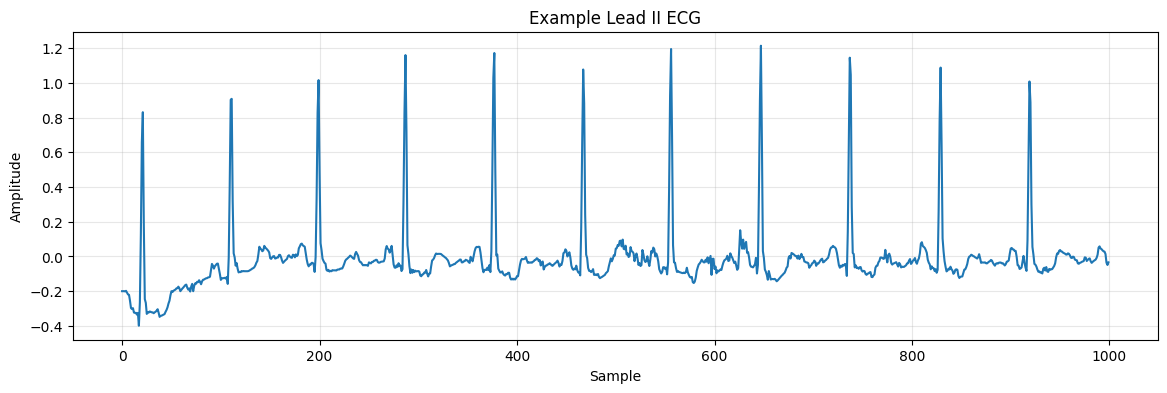

In [ ]:
lead_ii = example_record.p_signal[:, 1]

plt.figure(figsize=(14, 4))
plt.plot(lead_ii)
plt.title("Example Lead II ECG")
plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.grid(alpha=0.3)
plt.show()


In [ ]:
def bandpass_filter(
    signal,
    sampling_frequency=100
):
    low_cutoff = 0.5 / (
        sampling_frequency / 2
    )

    high_cutoff = 40.0 / (
        sampling_frequency / 2
    )

    b, a = butter(
        3,
        [
            low_cutoff,
            high_cutoff
        ],
        btype="band"
    )

    return filtfilt(
        b,
        a,
        signal
    )


In [ ]:
def preprocess_ecg(
    local_path,
    target_length=1000
):
    record = wfdb.rdrecord(
        local_path
    )

    # Lead II
    signal = record.p_signal[:, 1]
    signal = np.nan_to_num(
        signal
    ).astype(np.float32)

    signal = bandpass_filter(
        signal
    )

    # Truncate or pad to 1,000 values
    if len(signal) > target_length:
        signal = signal[:target_length]

    elif len(signal) < target_length:
        padding_length = (
            target_length - len(signal)
        )

        signal = np.pad(
            signal,
            (0, padding_length),
            mode="constant"
        )

    # Normalize this ECG independently
    signal = (
        signal - np.mean(signal)
    ) / (
        np.std(signal) + 1e-8
    )

    return signal.astype(
        np.float32
    )


In [ ]:
processed_signals = []
valid_rows = []

for _, row in tqdm(
    manifest.iterrows(),
    total=len(manifest),
    desc="Preprocessing ECG signals"
):
    try:
        signal = preprocess_ecg(
            row["local_path"]
        )

        processed_signals.append(
            signal
        )

        valid_rows.append(row)

    except Exception as error:
        print(
            "Could not process ECG",
            row["ecg_id"],
            error
        )

processed_manifest = pd.DataFrame(
    valid_rows
)

X = np.stack(
    processed_signals
)

print("Processed signal shape:", X.shape)
print("Processed metadata shape:",
      processed_manifest.shape)


Preprocessing ECG signals:   0%|          | 0/900 [00:00<?, ?it/s]

Processed signal shape: (900, 1000)
Processed metadata shape: (900, 31)


In [ ]:

CLASS_NAMES = [
    "AFIB",
    "SR",
    "STACH"
]

CLASS_TO_INDEX = {
    label: index
    for index, label in enumerate(
        CLASS_NAMES
    )
}

y = processed_manifest["label"].map(
    CLASS_TO_INDEX
).to_numpy()

groups = processed_manifest[
    "patient_id"
].to_numpy()

split_labels = processed_manifest[
    "split"
].to_numpy()

print("Class mapping:", CLASS_TO_INDEX)
print("Label shape:", y.shape)
print("Class counts:", np.bincount(y))


Class mapping: {'AFIB': 0, 'SR': 1, 'STACH': 2}
Label shape: (900,)
Class counts: [300 300 300]


In [ ]:
train_mask = split_labels == "train"
validation_mask = split_labels == "validation"
test_mask = split_labels == "test"

X_train = X[train_mask]
y_train = y[train_mask]
groups_train = groups[train_mask]

X_validation = X[validation_mask]
y_validation = y[validation_mask]

X_test = X[test_mask]
y_test = y[test_mask]

print("X_train:", X_train.shape)
print("X_validation:", X_validation.shape)
print("X_test:", X_test.shape)


X_train: (600, 1000)
X_validation: (150, 1000)
X_test: (150, 1000)


In [ ]:
np.save(
    "/content/X_train_ptbxl.npy",
    X_train
)

np.save(
    "/content/y_train_ptbxl.npy",
    y_train
)

np.save(
    "/content/X_validation_ptbxl.npy",
    X_validation
)

np.save(
    "/content/y_validation_ptbxl.npy",
    y_validation
)

np.save(
    "/content/X_test_ptbxl.npy",
    X_test
)

np.save(
    "/content/y_test_ptbxl.npy",
    y_test
)

processed_manifest.to_csv(
    "/content/ptbxl_processed_manifest.csv",
    index=False
)

print("Prepared data saved.")


Prepared data saved.


In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader

class ECGTensorDataset(Dataset):

    def __init__(self, signals, labels):
        self.signals = torch.tensor(
            signals,
            dtype=torch.float32
        ).unsqueeze(1)

        self.labels = torch.tensor(
            labels,
            dtype=torch.long
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return (
            self.signals[index],
            self.labels[index]
        )


In [ ]:
train_dataset = ECGTensorDataset(
    X_train,
    y_train
)

validation_dataset = ECGTensorDataset(
    X_validation,
    y_validation
)

test_dataset = ECGTensorDataset(
    X_test,
    y_test
)


In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=0
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

signals, labels = next(
    iter(train_loader)
)

print("Batch signal shape:", signals.shape)
print("Batch label shape:", labels.shape)


Batch signal shape: torch.Size([16, 1, 1000])
Batch label shape: torch.Size([16])


In [ ]:
!pip -q install pennylane


In [ ]:
import copy
import random
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import pennylane as qml

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

torch_device = torch.device("cpu")

N_QUBITS = 4
N_CLASSES = 3

print("Using device:", torch_device)


Using device: cpu


In [ ]:
class CNNFeatureExtractor(nn.Module):

    def __init__(self, output_features=4):
        super().__init__()

        self.convolution = nn.Sequential(
            nn.Conv1d(
                in_channels=1,
                out_channels=16,
                kernel_size=7,
                padding=3
            ),
            nn.BatchNorm1d(16),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(
                in_channels=16,
                out_channels=32,
                kernel_size=5,
                padding=2
            ),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(
                in_channels=32,
                out_channels=64,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm1d(64),
            nn.ReLU(),

            nn.AdaptiveAvgPool1d(1)
        )

        self.projection = nn.Linear(
            64,
            output_features
        )

    def forward(self, x):
        x = self.convolution(x)
        x = x.squeeze(-1)
        x = self.projection(x)

        return x


In [ ]:
quantum_device = qml.device(
    "default.qubit",
    wires=N_QUBITS
)

N_QUANTUM_LAYERS = 2

@qml.qnode(
    quantum_device,
    interface="torch"
)
def quantum_circuit(inputs, weights):

    qml.AngleEmbedding(
        inputs,
        wires=range(N_QUBITS),
        rotation="Y"
    )

    qml.StronglyEntanglingLayers(
        weights,
        wires=range(N_QUBITS)
    )

    return [
        qml.expval(qml.PauliZ(i))
        for i in range(N_QUBITS)
    ]

weight_shapes = {
    "weights": (
        N_QUANTUM_LAYERS,
        N_QUBITS,
        3
    )
}

def create_quantum_layer():
    return qml.qnn.TorchLayer(
        quantum_circuit,
        weight_shapes
    )


In [ ]:
class ClassicalCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.feature_extractor = CNNFeatureExtractor(
            output_features=N_QUBITS
        )

        self.classifier = nn.Linear(
            N_QUBITS,
            N_CLASSES
        )

    def forward(self, x):
        features = self.feature_extractor(x)
        output = self.classifier(features)

        return output


In [ ]:
class ClassicalCNNMLP(nn.Module):

    def __init__(self):
        super().__init__()

        self.feature_extractor = CNNFeatureExtractor(
            output_features=N_QUBITS
        )

        self.classifier = nn.Sequential(
            nn.Linear(N_QUBITS, 8),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(8, N_CLASSES)
        )

    def forward(self, x):
        features = self.feature_extractor(x)
        output = self.classifier(features)

        return output


In [ ]:
class HybridCNNVQC(nn.Module):

    def __init__(self):
        super().__init__()

        self.feature_extractor = CNNFeatureExtractor(
            output_features=N_QUBITS
        )

        # A new independent quantum layer
        # is created for every model instance
        self.quantum_layer = create_quantum_layer()

        self.classifier = nn.Linear(
            N_QUBITS,
            N_CLASSES
        )

    def forward(self, x):
        features = self.feature_extractor(x)

        # Convert CNN features to quantum rotation angles
        features = torch.tanh(features)
        features = (features + 1.0) * (
            np.pi / 2
        )

        quantum_output = self.quantum_layer(
            features
        )

        output = self.classifier(
            quantum_output
        )

        return output


In [ ]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


In [ ]:
def create_seeded_loaders(seed):

    generator = torch.Generator()
    generator.manual_seed(seed)

    seeded_train_loader = DataLoader(
        train_dataset,
        batch_size=16,
        shuffle=True,
        generator=generator,
        num_workers=0
    )

    seeded_validation_loader = DataLoader(
        validation_dataset,
        batch_size=16,
        shuffle=False,
        num_workers=0
    )

    seeded_test_loader = DataLoader(
        test_dataset,
        batch_size=16,
        shuffle=False,
        num_workers=0
    )

    return (
        seeded_train_loader,
        seeded_validation_loader,
        seeded_test_loader
    )


In [ ]:
classical_results, _, _ = evaluate_model(
    classical_model,
    test_loader_42
)

classical_mlp_results, _, _ = evaluate_model(
    classical_mlp_model,
    test_loader_42
)

hybrid_results, _, _ = evaluate_model(
    hybrid_model,
    test_loader_42
)

one_seed_results = pd.DataFrame([
    {
        "model": "Classical CNN",
        **classical_results
    },
    {
        "model": "Classical CNN-MLP",
        **classical_mlp_results
    },
    {
        "model": "Hybrid CNN-VQC",
        **hybrid_results
    }
])

one_seed_results


NameError: name 'classical_model' is not defined

In [ ]:
def evaluate_model(model, loader):

    model = model.to(torch_device)
    model.eval()

    true_labels = []
    predicted_labels = []

    with torch.no_grad():

        for signals, labels in loader:

            signals = signals.to(torch_device)
            labels = labels.to(torch_device)

            outputs = model(signals)

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            true_labels.extend(
                labels.cpu().numpy()
            )

            predicted_labels.extend(
                predictions.cpu().numpy()
            )

    true_labels = np.array(true_labels)
    predicted_labels = np.array(predicted_labels)

    results = {
        "accuracy": accuracy_score(
            true_labels,
            predicted_labels
        ),
        "balanced_accuracy": balanced_accuracy_score(
            true_labels,
            predicted_labels
        ),
        "macro_f1": f1_score(
            true_labels,
            predicted_labels,
            average="macro"
        )
    }

    return (
        results,
        true_labels,
        predicted_labels
    )


In [ ]:
def train_model(
    model,
    train_loader,
    validation_loader,
    epochs=15,
    learning_rate=0.001
):

    model = model.to(torch_device)

    loss_function = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    best_model_state = None
    best_validation_f1 = -1
    history = []

    for epoch in range(epochs):

        model.train()
        total_loss = 0.0

        for signals, labels in train_loader:

            signals = signals.to(torch_device)
            labels = labels.to(torch_device)

            optimizer.zero_grad()

            outputs = model(signals)

            loss = loss_function(
                outputs,
                labels
            )

            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        validation_results, _, _ = evaluate_model(
            model,
            validation_loader
        )

        average_loss = (
            total_loss / len(train_loader)
        )

        history.append({
            "epoch": epoch + 1,
            "loss": average_loss,
            **validation_results
        })

        if (
            validation_results["macro_f1"]
            > best_validation_f1
        ):
            best_validation_f1 = (
                validation_results["macro_f1"]
            )

            best_model_state = copy.deepcopy(
                model.state_dict()
            )

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Loss: {average_loss:.4f} | "
            f"Validation macro-F1: "
            f"{validation_results['macro_f1']:.4f}"
        )

    model.load_state_dict(
        best_model_state
    )

    return model, pd.DataFrame(history)


In [ ]:
set_seed(42)

(
    train_loader_42,
    validation_loader_42,
    test_loader_42
) = create_seeded_loaders(42)


In [ ]:
classical_model = ClassicalCNN()

classical_model, classical_history = train_model(
    classical_model,
    train_loader_42,
    validation_loader_42,
    epochs=15,
    learning_rate=0.001
)


Epoch 1/15 | Loss: 1.0549 | Validation macro-F1: 0.4353
Epoch 2/15 | Loss: 0.9225 | Validation macro-F1: 0.6231
Epoch 3/15 | Loss: 0.8182 | Validation macro-F1: 0.6419
Epoch 4/15 | Loss: 0.7424 | Validation macro-F1: 0.6815
Epoch 5/15 | Loss: 0.6629 | Validation macro-F1: 0.6899
Epoch 6/15 | Loss: 0.6204 | Validation macro-F1: 0.6965
Epoch 7/15 | Loss: 0.5631 | Validation macro-F1: 0.7070
Epoch 8/15 | Loss: 0.5132 | Validation macro-F1: 0.7569
Epoch 9/15 | Loss: 0.5069 | Validation macro-F1: 0.7105
Epoch 10/15 | Loss: 0.4672 | Validation macro-F1: 0.7682
Epoch 11/15 | Loss: 0.4321 | Validation macro-F1: 0.7329
Epoch 12/15 | Loss: 0.3871 | Validation macro-F1: 0.8190
Epoch 13/15 | Loss: 0.4192 | Validation macro-F1: 0.8072
Epoch 14/15 | Loss: 0.3821 | Validation macro-F1: 0.7845
Epoch 15/15 | Loss: 0.3962 | Validation macro-F1: 0.8260


In [ ]:
classical_mlp_model = ClassicalCNNMLP()

classical_mlp_model, classical_mlp_history = train_model(
    classical_mlp_model,
    train_loader_42,
    validation_loader_42,
    epochs=15,
    learning_rate=0.001
)


Epoch 1/15 | Loss: 1.0882 | Validation macro-F1: 0.3024
Epoch 2/15 | Loss: 1.0359 | Validation macro-F1: 0.4065
Epoch 3/15 | Loss: 0.9488 | Validation macro-F1: 0.5629
Epoch 4/15 | Loss: 0.8635 | Validation macro-F1: 0.5186
Epoch 5/15 | Loss: 0.7885 | Validation macro-F1: 0.6900
Epoch 6/15 | Loss: 0.7284 | Validation macro-F1: 0.6325
Epoch 7/15 | Loss: 0.7116 | Validation macro-F1: 0.7042
Epoch 8/15 | Loss: 0.6767 | Validation macro-F1: 0.7389
Epoch 9/15 | Loss: 0.6231 | Validation macro-F1: 0.7451
Epoch 10/15 | Loss: 0.5783 | Validation macro-F1: 0.7402
Epoch 11/15 | Loss: 0.5662 | Validation macro-F1: 0.6486
Epoch 12/15 | Loss: 0.5472 | Validation macro-F1: 0.7324
Epoch 13/15 | Loss: 0.4925 | Validation macro-F1: 0.7694
Epoch 14/15 | Loss: 0.4948 | Validation macro-F1: 0.7884
Epoch 15/15 | Loss: 0.4953 | Validation macro-F1: 0.7025


In [ ]:
hybrid_model = HybridCNNVQC()

hybrid_model, hybrid_history = train_model(
    hybrid_model,
    train_loader_42,
    validation_loader_42,
    epochs=15,
    learning_rate=0.001
)


Epoch 1/15 | Loss: 1.1042 | Validation macro-F1: 0.2092
Epoch 2/15 | Loss: 1.0786 | Validation macro-F1: 0.3455
Epoch 3/15 | Loss: 1.0427 | Validation macro-F1: 0.2950
Epoch 4/15 | Loss: 1.0154 | Validation macro-F1: 0.4304
Epoch 5/15 | Loss: 0.9987 | Validation macro-F1: 0.4021
Epoch 6/15 | Loss: 0.9630 | Validation macro-F1: 0.6370
Epoch 7/15 | Loss: 0.9358 | Validation macro-F1: 0.6569
Epoch 8/15 | Loss: 0.9035 | Validation macro-F1: 0.6356
Epoch 9/15 | Loss: 0.8801 | Validation macro-F1: 0.6573
Epoch 10/15 | Loss: 0.8434 | Validation macro-F1: 0.4074
Epoch 11/15 | Loss: 0.8249 | Validation macro-F1: 0.4971
Epoch 12/15 | Loss: 0.7925 | Validation macro-F1: 0.6648
Epoch 13/15 | Loss: 0.7647 | Validation macro-F1: 0.6273
Epoch 14/15 | Loss: 0.7251 | Validation macro-F1: 0.7579
Epoch 15/15 | Loss: 0.6664 | Validation macro-F1: 0.7655


In [ ]:
classical_results, _, _ = evaluate_model(
    classical_model,
    test_loader_42
)

classical_mlp_results, _, _ = evaluate_model(
    classical_mlp_model,
    test_loader_42
)

hybrid_results, _, _ = evaluate_model(
    hybrid_model,
    test_loader_42
)

one_seed_results = pd.DataFrame([
    {
        "model": "Classical CNN",
        **classical_results
    },
    {
        "model": "Classical CNN-MLP",
        **classical_mlp_results
    },
    {
        "model": "Hybrid CNN-VQC",
        **hybrid_results
    }
])

one_seed_results


,model,accuracy,balanced_accuracy,macro_f1
0,Classical CNN,0.820000,0.820000,0.819046
1,Classical CNN-MLP,0.740000,0.740000,0.736782
2,Hybrid CNN-VQC,0.793333,0.793333,0.785346


In [ ]:
SEEDS = [42, 123, 2026]

all_seed_results = []

for seed in SEEDS:

    print("\n" + "=" * 60)
    print(f"Starting seed: {seed}")
    print("=" * 60)

    set_seed(seed)

    (
        train_loader_seed,
        validation_loader_seed,
        test_loader_seed
    ) = create_seeded_loaders(seed)

    model_dictionary = {
        "Classical CNN": ClassicalCNN(),
        "Classical CNN-MLP": ClassicalCNNMLP(),
        "Hybrid CNN-VQC": HybridCNNVQC()
    }

    for model_name, model in model_dictionary.items():

        print(f"\nTraining {model_name}")

        start_time = time.perf_counter()

        trained_model, history = train_model(
            model,
            train_loader_seed,
            validation_loader_seed,
            epochs=15,
            learning_rate=0.001
        )

        training_time = (
            time.perf_counter() - start_time
        )

        test_results, y_true, y_pred = evaluate_model(
            trained_model,
            test_loader_seed
        )

        all_seed_results.append({
            "seed": seed,
            "model": model_name,
            "training_time_sec": training_time,
            **test_results
        })

        print(test_results)



Starting seed: 42

Training Classical CNN
Epoch 1/15 | Loss: 1.0549 | Validation macro-F1: 0.4353
Epoch 2/15 | Loss: 0.9225 | Validation macro-F1: 0.6231
Epoch 3/15 | Loss: 0.8182 | Validation macro-F1: 0.6419
Epoch 4/15 | Loss: 0.7424 | Validation macro-F1: 0.6815
Epoch 5/15 | Loss: 0.6629 | Validation macro-F1: 0.6899
Epoch 6/15 | Loss: 0.6204 | Validation macro-F1: 0.6965
Epoch 7/15 | Loss: 0.5631 | Validation macro-F1: 0.7070
Epoch 8/15 | Loss: 0.5132 | Validation macro-F1: 0.7569
Epoch 9/15 | Loss: 0.5069 | Validation macro-F1: 0.7105
Epoch 10/15 | Loss: 0.4672 | Validation macro-F1: 0.7682
Epoch 11/15 | Loss: 0.4321 | Validation macro-F1: 0.7329
Epoch 12/15 | Loss: 0.3871 | Validation macro-F1: 0.8190
Epoch 13/15 | Loss: 0.4192 | Validation macro-F1: 0.8072
Epoch 14/15 | Loss: 0.3821 | Validation macro-F1: 0.7845
Epoch 15/15 | Loss: 0.3962 | Validation macro-F1: 0.8260
{'accuracy': 0.82, 'balanced_accuracy': np.float64(0.82), 'macro_f1': 0.8190456517248502}

Training Classical C

In [ ]:
all_seed_results_df = pd.DataFrame(
    all_seed_results
)

summary_results = (
    all_seed_results_df
    .groupby("model")
    .agg(
        accuracy_mean=("accuracy", "mean"),
        accuracy_std=("accuracy", "std"),

        balanced_accuracy_mean=(
            "balanced_accuracy",
            "mean"
        ),
        balanced_accuracy_std=(
            "balanced_accuracy",
            "std"
        ),

        macro_f1_mean=("macro_f1", "mean"),
        macro_f1_std=("macro_f1", "std"),

        average_training_time_sec=(
            "training_time_sec",
            "mean"
        )
    )
    .reset_index()
)

summary_results


,model,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,macro_f1_mean,macro_f1_std,average_training_time_sec
0,Classical CNN,0.811111,0.027756,0.811111,0.027756,0.804903,0.031970,14.761332
1,Classical CNN-MLP,0.737778,0.068096,0.737778,0.068096,0.733639,0.074315,12.565254
2,Hybrid CNN-VQC,0.722222,0.111820,0.722222,0.111820,0.720672,0.108862,27.531518


In [ ]:
all_seed_results_df.sort_values(
    ["model", "seed"]
)



,seed,model,training_time_sec,accuracy,balanced_accuracy,macro_f1
0,42,Classical CNN,19.038548,0.820000,0.820000,0.819046
3,123,Classical CNN,12.445508,0.833333,0.833333,0.827362
6,2026,Classical CNN,12.799940,0.780000,0.780000,0.768300
1,42,Classical CNN-MLP,12.658970,0.766667,0.766667,0.765390
4,123,Classical CNN-MLP,12.465432,0.786667,0.786667,0.786805
7,2026,Classical CNN-MLP,12.571360,0.660000,0.660000,0.648723
2,42,Hybrid CNN-VQC,27.264165,0.793333,0.793333,0.789443
5,123,Hybrid CNN-VQC,27.779189,0.593333,0.593333,0.595160
8,2026,Hybrid CNN-VQC,27.551201,0.780000,0.780000,0.777412


In [ ]:
set_seed(42)

(
    train_loader_42,
    validation_loader_42,
    test_loader_42
) = create_seeded_loaders(42)


NameError: name 'DataLoader' is not defined

In [ ]:
import copy
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import pennylane as qml

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)


In [ ]:
torch_device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Torch device:", torch_device)


Torch device: cuda


In [ ]:
N_QUBITS = 4
N_CLASSES = 3

class CNNFeatureExtractor(nn.Module):

    def __init__(self, output_features=4):
        super().__init__()

        self.convolution = nn.Sequential(
            nn.Conv1d(
                1,
                16,
                kernel_size=7,
                padding=3
            ),
            nn.BatchNorm1d(16),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(
                16,
                32,
                kernel_size=5,
                padding=2
            ),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(
                32,
                64,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm1d(64),
            nn.ReLU(),

            nn.AdaptiveAvgPool1d(1)
        )

        self.projection = nn.Linear(
            64,
            output_features
        )

    def forward(self, x):
        x = self.convolution(x)
        x = x.squeeze(-1)
        x = self.projection(x)

        return x


In [ ]:
quantum_device = qml.device(
    "default.qubit",
    wires=N_QUBITS
)

N_QUANTUM_LAYERS = 2

@qml.qnode(
    quantum_device,
    interface="torch"
)
def quantum_circuit(inputs, weights):

    qml.AngleEmbedding(
        inputs,
        wires=range(N_QUBITS),
        rotation="Y"
    )

    qml.StronglyEntanglingLayers(
        weights,
        wires=range(N_QUBITS)
    )

    return [
        qml.expval(qml.PauliZ(i))
        for i in range(N_QUBITS)
    ]

weight_shapes = {
    "weights": (
        N_QUANTUM_LAYERS,
        N_QUBITS,
        3
    )
}

quantum_layer = qml.qnn.TorchLayer(
    quantum_circuit,
    weight_shapes
)


In [ ]:
class ClassicalCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.feature_extractor = CNNFeatureExtractor(
            output_features=N_QUBITS
        )

        self.classifier = nn.Linear(
            N_QUBITS,
            N_CLASSES
        )

    def forward(self, x):
        features = self.feature_extractor(x)
        output = self.classifier(features)

        return output


In [ ]:
class HybridCNNVQC(nn.Module):

    def __init__(self):
        super().__init__()

        self.feature_extractor = CNNFeatureExtractor(
            output_features=N_QUBITS
        )

        self.quantum_layer = quantum_layer

        self.classifier = nn.Linear(
            N_QUBITS,
            N_CLASSES
        )

    def forward(self, x):
        features = self.feature_extractor(x)

        # Convert CNN features into quantum rotation angles
        features = torch.tanh(features)
        features = (features + 1.0) * (
            np.pi / 2
        )

        quantum_output = self.quantum_layer(
            features
        )

        output = self.classifier(
            quantum_output
        )

        return output


In [ ]:
def evaluate_model(model, loader):
    model.eval()

    true_labels = []
    predicted_labels = []

    with torch.no_grad():
        for signals, labels in loader:
            signals = signals.to(torch_device)
            labels = labels.to(torch_device)

            outputs = model(signals)
            predictions = torch.argmax(
                outputs,
                dim=1
            )

            true_labels.extend(
                labels.cpu().numpy()
            )

            predicted_labels.extend(
                predictions.cpu().numpy()
            )

    true_labels = np.array(true_labels)
    predicted_labels = np.array(predicted_labels)

    results = {
        "accuracy": accuracy_score(
            true_labels,
            predicted_labels
        ),
        "balanced_accuracy": balanced_accuracy_score(
            true_labels,
            predicted_labels
        ),
        "macro_f1": f1_score(
            true_labels,
            predicted_labels,
            average="macro"
        )
    }

    return (
        results,
        true_labels,
        predicted_labels
    )


In [ ]:
def train_model(
    model,
    train_loader,
    validation_loader,
    epochs=15,
    learning_rate=0.001
):
    model = model.to(torch_device)

    loss_function = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    best_model_state = None
    best_validation_f1 = -1
    history = []

    for epoch in range(epochs):

        model.train()
        total_loss = 0.0

        for signals, labels in train_loader:
            signals = signals.to(torch_device)
            labels = labels.to(torch_device)

            optimizer.zero_grad()

            outputs = model(signals)
            loss = loss_function(
                outputs,
                labels
            )

            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        validation_results, _, _ = evaluate_model(
            model,
            validation_loader
        )

        average_loss = (
            total_loss / len(train_loader)
        )

        history.append({
            "epoch": epoch + 1,
            "loss": average_loss,
            **validation_results
        })

        if (
            validation_results["macro_f1"]
            > best_validation_f1
        ):
            best_validation_f1 = (
                validation_results["macro_f1"]
            )

            best_model_state = copy.deepcopy(
                model.state_dict()
            )

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Loss: {average_loss:.4f} | "
            f"Validation macro-F1: "
            f"{validation_results['macro_f1']:.4f}"
        )

    model.load_state_dict(
        best_model_state
    )

    return model, pd.DataFrame(history)


In [ ]:
classical_model = ClassicalCNN()

start_time = time.perf_counter()

classical_model, classical_history = train_model(
    classical_model,
    train_loader,
    validation_loader,
    epochs=15,
    learning_rate=0.001
)

classical_training_time = (
    time.perf_counter() - start_time
)

print(
    "Classical training time:",
    classical_training_time
)


Epoch 1/15 | Loss: 1.0607 | Validation macro-F1: 0.4820
Epoch 2/15 | Loss: 0.9734 | Validation macro-F1: 0.5043
Epoch 3/15 | Loss: 0.9167 | Validation macro-F1: 0.5894
Epoch 4/15 | Loss: 0.8589 | Validation macro-F1: 0.5857
Epoch 5/15 | Loss: 0.8255 | Validation macro-F1: 0.6373
Epoch 6/15 | Loss: 0.7576 | Validation macro-F1: 0.6778
Epoch 7/15 | Loss: 0.6974 | Validation macro-F1: 0.7028
Epoch 8/15 | Loss: 0.6151 | Validation macro-F1: 0.6851
Epoch 9/15 | Loss: 0.6046 | Validation macro-F1: 0.7397
Epoch 10/15 | Loss: 0.5643 | Validation macro-F1: 0.7272
Epoch 11/15 | Loss: 0.5328 | Validation macro-F1: 0.7327
Epoch 12/15 | Loss: 0.4794 | Validation macro-F1: 0.7745
Epoch 13/15 | Loss: 0.4483 | Validation macro-F1: 0.7721
Epoch 14/15 | Loss: 0.4368 | Validation macro-F1: 0.8095
Epoch 15/15 | Loss: 0.4028 | Validation macro-F1: 0.7808
Classical training time: 8.537297005000255


In [ ]:
# Use CPU for the hybrid quantum-classical model
torch_device = torch.device("cpu")

print("Hybrid model device:", torch_device)


Hybrid model device: cpu


In [ ]:
hybrid_model = HybridCNNVQC()


In [ ]:
hybrid_model = HybridCNNVQC()

start_time = time.perf_counter()

hybrid_model, hybrid_history = train_model(
    hybrid_model,
    train_loader,
    validation_loader,
    epochs=15,
    learning_rate=0.001
)

hybrid_training_time = (
    time.perf_counter() - start_time
)

print(
    "Hybrid training time:",
    hybrid_training_time
)


Epoch 1/15 | Loss: 1.0680 | Validation macro-F1: 0.3163
Epoch 2/15 | Loss: 0.9699 | Validation macro-F1: 0.5160
Epoch 3/15 | Loss: 0.8856 | Validation macro-F1: 0.6249
Epoch 4/15 | Loss: 0.8332 | Validation macro-F1: 0.5402
Epoch 5/15 | Loss: 0.7861 | Validation macro-F1: 0.6243
Epoch 6/15 | Loss: 0.7529 | Validation macro-F1: 0.6158
Epoch 7/15 | Loss: 0.7139 | Validation macro-F1: 0.6869
Epoch 8/15 | Loss: 0.7000 | Validation macro-F1: 0.4769
Epoch 9/15 | Loss: 0.6802 | Validation macro-F1: 0.6651
Epoch 10/15 | Loss: 0.6628 | Validation macro-F1: 0.7136
Epoch 11/15 | Loss: 0.6119 | Validation macro-F1: 0.7733
Epoch 12/15 | Loss: 0.5880 | Validation macro-F1: 0.7928
Epoch 13/15 | Loss: 0.5390 | Validation macro-F1: 0.7803
Epoch 14/15 | Loss: 0.5351 | Validation macro-F1: 0.7564
Epoch 15/15 | Loss: 0.4811 | Validation macro-F1: 0.7950
Hybrid training time: 30.8116380030001


In [ ]:
torch_device = torch.device("cpu")

classical_model = classical_model.to(torch_device)
hybrid_model = hybrid_model.to(torch_device)

print("Classical model device:", next(classical_model.parameters()).device)
print("Hybrid model device:", next(hybrid_model.parameters()).device)


Classical model device: cpu
Hybrid model device: cpu


In [ ]:
def evaluate_model(model, loader):
    model = model.to(torch_device)
    model.eval()

    true_labels = []
    predicted_labels = []

    with torch.no_grad():
        for signals, labels in loader:
            signals = signals.to(torch_device)
            labels = labels.to(torch_device)

            outputs = model(signals)

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            true_labels.extend(
                labels.cpu().numpy()
            )

            predicted_labels.extend(
                predictions.cpu().numpy()
            )

    true_labels = np.array(true_labels)
    predicted_labels = np.array(predicted_labels)

    results = {
        "accuracy": accuracy_score(
            true_labels,
            predicted_labels
        ),
        "balanced_accuracy": balanced_accuracy_score(
            true_labels,
            predicted_labels
        ),
        "macro_f1": f1_score(
            true_labels,
            predicted_labels,
            average="macro"
        )
    }

    return (
        results,
        true_labels,
        predicted_labels
    )


In [ ]:
classical_results, y_true_classical, y_pred_classical = evaluate_model(
    classical_model,
    test_loader
)

hybrid_results, y_true_hybrid, y_pred_hybrid = evaluate_model(
    hybrid_model,
    test_loader
)

comparison = pd.DataFrame([
    {
        "model": "Classical CNN",
        **classical_results,
        "training_time_sec": classical_training_time
    },
    {
        "model": "Hybrid CNN-VQC",
        **hybrid_results,
        "training_time_sec": hybrid_training_time
    }
])

comparison


,model,accuracy,balanced_accuracy,macro_f1,training_time_sec
0,Classical CNN,0.793333,0.793333,0.793445,8.537297
1,Hybrid CNN-VQC,0.840000,0.840000,0.839425,30.811638


In [ ]:
CLASS_NAMES = [
    "AFIB",
    "SR",
    "STACH"
]

print("Classical CNN report")
print(
    classification_report(
        y_true_classical,
        y_pred_classical,
        target_names=CLASS_NAMES,
        zero_division=0
    )
)

print("Hybrid CNN-VQC report")
print(
    classification_report(
        y_true_hybrid,
        y_pred_hybrid,
        target_names=CLASS_NAMES,
        zero_division=0
    )
)


Classical CNN report
              precision    recall  f1-score   support

        AFIB       0.71      0.88      0.79        50
          SR       0.79      0.82      0.80        50
       STACH       0.94      0.68      0.79        50

    accuracy                           0.79       150
   macro avg       0.81      0.79      0.79       150
weighted avg       0.81      0.79      0.79       150

Hybrid CNN-VQC report
              precision    recall  f1-score   support

        AFIB       0.90      0.86      0.88        50
          SR       0.83      0.76      0.79        50
       STACH       0.80      0.90      0.85        50

    accuracy                           0.84       150
   macro avg       0.84      0.84      0.84       150
weighted avg       0.84      0.84      0.84       150



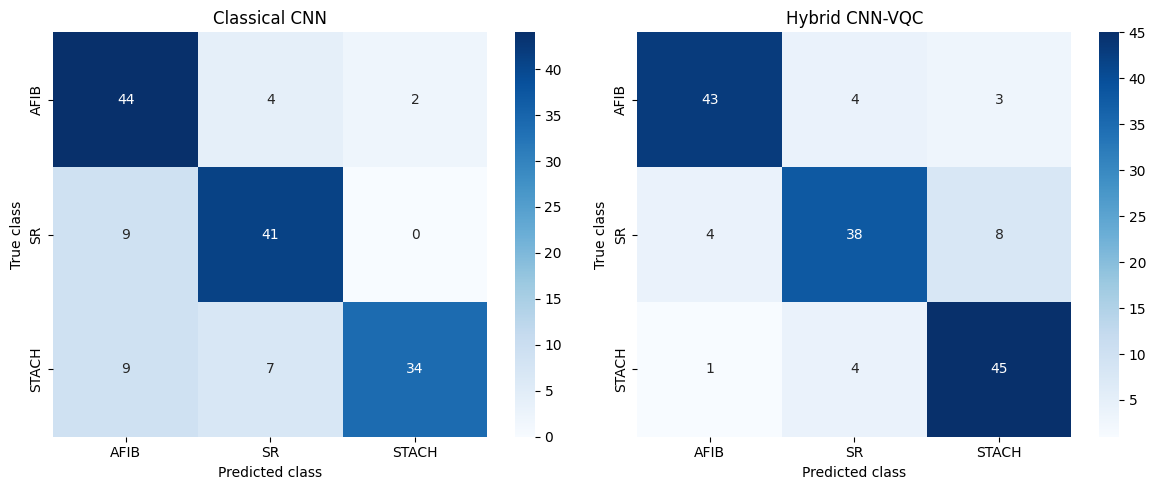

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 5)
)

for ax, true_labels, predictions, title in [
    (
        axes[0],
        y_true_classical,
        y_pred_classical,
        "Classical CNN"
    ),
    (
        axes[1],
        y_true_hybrid,
        y_pred_hybrid,
        "Hybrid CNN-VQC"
    )
]:

    matrix = confusion_matrix(
        true_labels,
        predictions
    )

    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES,
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")

plt.tight_layout()
plt.show()


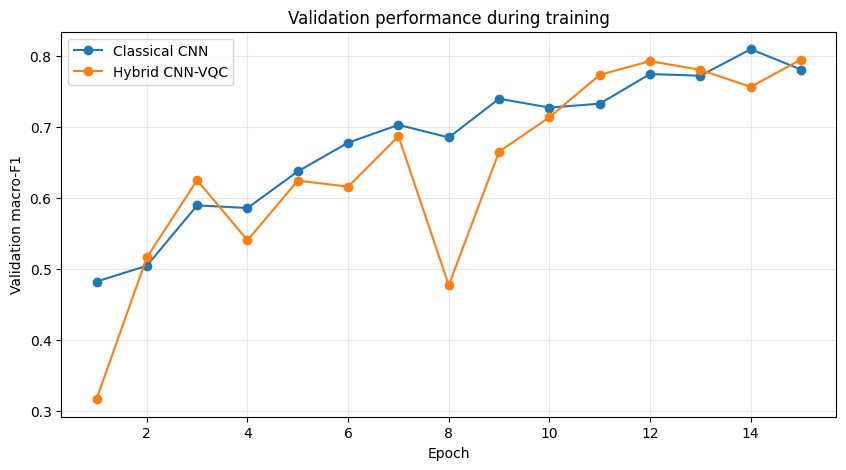

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    classical_history["epoch"],
    classical_history["macro_f1"],
    marker="o",
    label="Classical CNN"
)

plt.plot(
    hybrid_history["epoch"],
    hybrid_history["macro_f1"],
    marker="o",
    label="Hybrid CNN-VQC"
)

plt.xlabel("Epoch")
plt.ylabel("Validation macro-F1")
plt.title("Validation performance during training")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [ ]:
comparison.to_csv(
    "/content/cnn_vqc_test_results.csv",
    index=False
)

classical_history.to_csv(
    "/content/classical_cnn_history.csv",
    index=False
)

hybrid_history.to_csv(
    "/content/hybrid_cnn_vqc_history.csv",
    index=False
)

torch.save(
    classical_model.state_dict(),
    "/content/classical_cnn_model.pt"
)

torch.save(
    hybrid_model.state_dict(),
    "/content/hybrid_cnn_vqc_model.pt"
)
